## Exp.No : 7 HOUGH TRANSFORM
## NAME : SADHANA S
## REG.NO : 212224230234

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread(r"C:\Users\admin\Downloads\mypic.jpeg")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [3]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

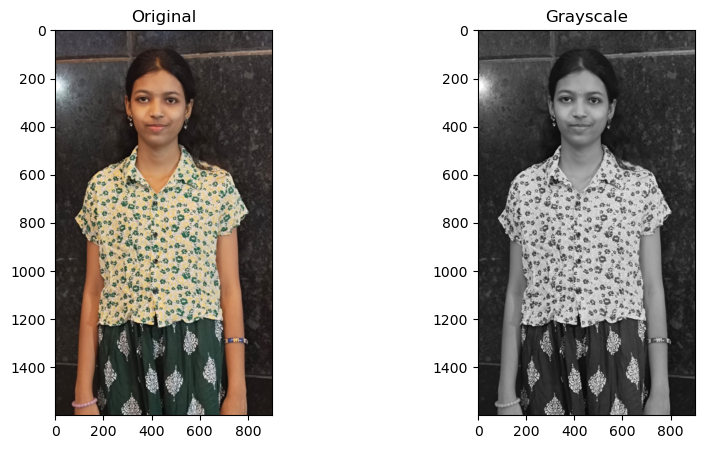

In [4]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.imshow(image_rgb); plt.title("Original")
plt.subplot(1,2,2); plt.imshow(gray, cmap='gray'); plt.title("Grayscale")
plt.show()

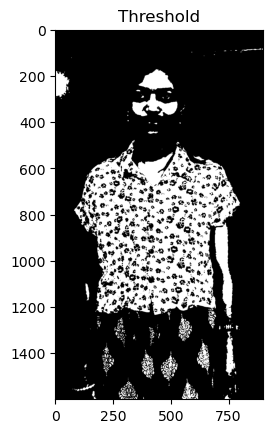

In [5]:
threshold = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)[1]
plt.imshow(threshold, cmap='gray')
plt.title("Threshold")
plt.show()

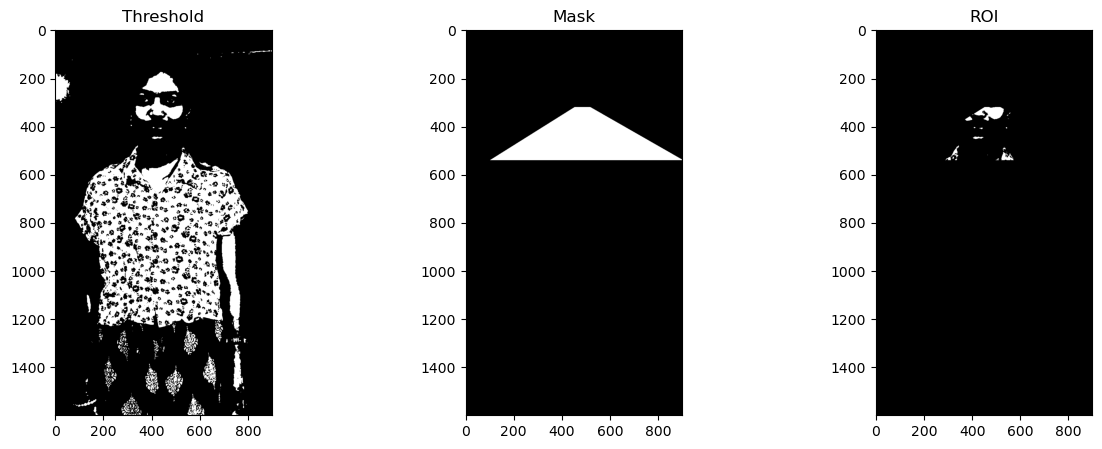

In [6]:
roi_vertices = np.array([[[100,540],[900,540],[515,320],[450,320]]])
mask = np.zeros_like(threshold)
cv2.fillPoly(mask, roi_vertices, 255)
roi = cv2.bitwise_and(threshold, mask)

plt.figure(figsize=(15,5))
for i, (img, title) in enumerate([(threshold,"Threshold"),(mask,"Mask"),(roi,"ROI")]):
    plt.subplot(1,3,i+1); plt.imshow(img,cmap='gray'); plt.title(title)
plt.show()

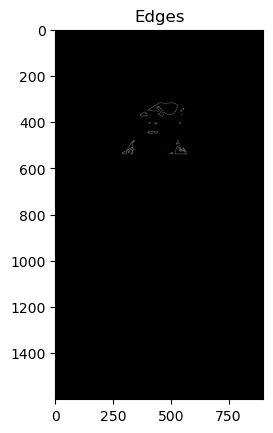

In [7]:
edges = cv2.Canny(roi, 50, 150)
plt.imshow(edges, cmap='gray')
plt.title("Edges")
plt.show()

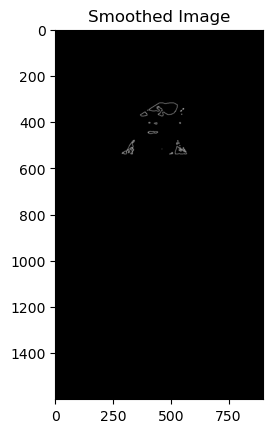

In [8]:
blurred = cv2.GaussianBlur(edges, (5,5), 0)
plt.imshow(blurred, cmap='gray')
plt.title("Smoothed Image")
plt.show()

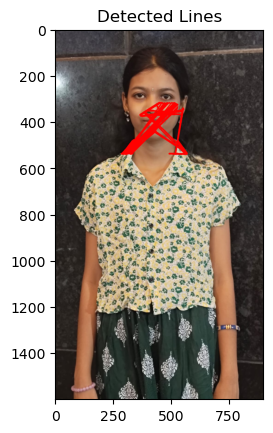

In [9]:
lines = cv2.HoughLinesP(blurred, 1, np.pi/180, 50, minLineLength=50, maxLineGap=100)
line_image = image_rgb.copy()

if lines is not None:
    for x1,y1,x2,y2 in np.array(lines).reshape(-1,4):
        cv2.line(line_image, (x1,y1), (x2,y2), (255,0,0), 3)

plt.imshow(line_image)
plt.title("Detected Lines")
plt.show()

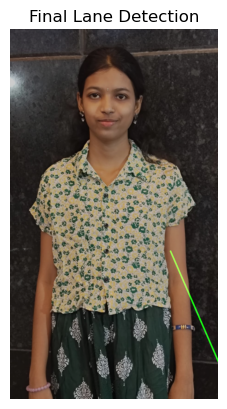

In [11]:
lane = np.zeros_like(image_rgb)
h, w = image.shape[:2]

if lines is not None:
    left, right = [], []

    for x1,y1,x2,y2 in np.array(lines).reshape(-1,4):
        if x2 != x1:
            slope = (y2-y1)/(x2-x1)
            (left if slope < 0 else right).append((x1,y1,x2,y2))

    for group in [left, right]:
        if group:
            p = np.array(group)
            fit = np.polyfit(np.r_[p[:,1],p[:,3]], np.r_[p[:,0],p[:,2]], 1)
            cv2.line(lane, (int(np.polyval(fit,h)),h),
                     (int(np.polyval(fit,h*0.6)),int(h*0.6)), (0,255,0), 5)

final_output = cv2.addWeighted(image_rgb, 0.8, lane, 1, 0)

plt.imshow(final_output)
plt.title("Final Lane Detection")
plt.axis("off")
plt.show()